In [1]:
# Install required packages
!pip install rasterio albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 60.3 MB/s eta 0:00:00:00:0100:01


In [2]:
# Import libraries
import os
import numpy as np
import rasterio
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import albumentations

/usr/local/lib/python3.11/dist-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.5'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [3]:
# Normalize SAR image
import rasterio
import numpy as np
import os
from rasterio.io import MemoryFile

def normalize_stacked_raster(raster, output_path=None, save_to_disk=True):
    """
    Normalizes each band in a stacked raster individually (ignoring 0s),
    replaces NoData/NaNs with 0, and optionally saves the normalized result.

    Parameters:
    - raster: an open rasterio dataset (not a file path)
    - output_path: path to save the normalized stacked raster (required if save_to_disk is True)
    - save_to_disk: whether to save the output to disk

    Returns:
    - rasterio dataset of normalized stacked raster (MemoryFile or disk-based)
    """
    profile = raster.profile.copy()
    count = raster.count
    dtype = rasterio.float32
    nodata_val = 0.0  # Explicitly using 0 for NaN values
    profile.update(dtype=dtype, nodata=nodata_val)

    if save_to_disk:
        if not output_path:
            raise ValueError("output_path must be provided when save_to_disk is True.")
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        dst = rasterio.open(output_path, 'w', **profile)
    else:
        memfile = MemoryFile()
        dst = memfile.open(**profile)

    for i in range(1, count + 1):
        band = raster.read(i).astype(np.float32)
        
        # Handle NoData values
        nodata = raster.nodata
        if nodata is not None:
            band[band == nodata] = np.nan  # First convert nodata to NaN
            
        # Create mask excluding zeros and nodata/NaN values
        mask = (band != 0) & ~np.isnan(band)
        
        if np.any(mask):
            min_val = np.nanmin(band[mask])
            max_val = np.nanmax(band[mask])

            if max_val > min_val:
                # Normalize valid pixels to 0-1 range
                band[mask] = (band[mask] - min_val) / (max_val - min_val)

        # Explicitly assign 0 to NaN values (as requested)
        band = np.where(np.isnan(band), 0.0, band)
        
        dst.write(band, i)

    dst.close()

    if save_to_disk:
        print(f"✅ Normalized stacked raster saved at: {output_path}")
        return rasterio.open(output_path)
    else:
        print("✅ Normalized stacked raster stored in memory (not saved to disk)")
        return memfile.open()

# Kaggle-specific paths:
input_path = "/kaggle/input/ship-detecion-dataset/clip_of_ship.tif"
output_path = "/kaggle/working/clip_of_ship_normalized.tif"

# Run the normalization
with rasterio.open(input_path) as src:
    normalized_raster = normalize_stacked_raster(
        raster=src,
        output_path=output_path,
        save_to_disk=True
    )

✅ Normalized stacked raster saved at: /kaggle/working/clip_of_ship_normalized.tif


In [4]:
# Dataset class with augmentation
class ShipDatasetPatches(Dataset):
    def __init__(self, sar_image, mask_image, patch_size=256, stride=128):
        self.patches = []
        self.patch_size = patch_size
        self.aug = albumentations.Compose([
            albumentations.HorizontalFlip(p=0.5),
            albumentations.VerticalFlip(p=0.5),
            albumentations.Rotate(limit=45, p=0.5)
        ])
        _, H, W = sar_image.shape
        for i in range(0, H - patch_size + 1, stride):
            for j in range(0, W - patch_size + 1, stride):
                img_patch = sar_image[:, i:i+patch_size, j:j+patch_size]  # Fixed syntax error
                mask_patch = mask_image[i:i+patch_size, j:j+patch_size]
                self.patches.append((img_patch, mask_patch))
        print(f"Created {len(self.patches)} patches")  # Debug print
    
    def __len__(self):
        return len(self.patches)
    
    def __getitem__(self, idx):
        img_patch, mask_patch = self.patches[idx]
        augmented = self.aug(image=img_patch.transpose(1, 2, 0), mask=mask_patch)
        img_patch = augmented['image'].transpose(2, 0, 1)
        mask_patch = augmented['mask']
        return torch.tensor(img_patch, dtype=torch.float32), torch.tensor(mask_patch, dtype=torch.float32).unsqueeze(0)

In [5]:
# UNet model with batch normalization
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    
    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2):  # Changed to 2 for SAR polarizations
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.pool = nn.MaxPool2d(2)
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec2 = DoubleConv(256 + 128, 128)
        self.dec1 = DoubleConv(128 + 64, 64)
        self.final = nn.Conv2d(64, 1, kernel_size=1)
    
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        d2 = self.up1(e3)
        if d2.size(2) != e2.size(2) or d2.size(3) != e2.size(3):
            diffY = e2.size(2) - d2.size(2)
            diffX = e2.size(3) - d2.size(3)
            e2 = e2[:, :, diffY // 2 : e2.size(2) - (diffY - diffY // 2), diffX // 2 : e2.size(3) - (diffX - diffX // 2)]
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)
        d1 = self.up2(d2)
        if d1.size(2) != e1.size(2) or d1.size(3) != e1.size(3):
            diffY = e1.size(2) - d1.size(2)
            diffX = e1.size(3) - d1.size(3)
            e1 = e1[:, :, diffY // 2 : e1.size(2) - (diffY - diffY // 2), diffX // 2 : e1.size(3) - (diffX - diffX // 2)]
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        out = torch.sigmoid(self.final(d1))
        return out

In [6]:
# Dice + BCE Loss
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce_loss = nn.BCELoss()
    
    def forward(self, pred, target):
        smooth = 1e-6
        pred = pred.contiguous().view(-1)
        target = target.contiguous().view(-1)
        intersection = (pred * target).sum()
        dice_loss = 1 - (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)
        bce_loss = self.bce_loss(pred, target)
        return bce_loss + dice_loss

In [7]:
# Load data
with rasterio.open("/kaggle/working/clip_of_ship_normalized.tif") as src:
    sar_image = src.read().astype(np.float32)
    print(f"SAR Image Shape: {sar_image.shape}, Dtype: {sar_image.dtype}")  # Debug print
with rasterio.open("/kaggle/input/ship-detecion-dataset/ship_detection_bw.tif") as src:
    mask_image = src.read(1).astype(np.uint8)
    mask_image = (mask_image > 0).astype(np.float32)
    print(f"Mask Shape: {mask_image.shape}, Dtype: {mask_image.dtype}, Unique Values: {np.unique(mask_image)}")  # Debug print

SAR Image Shape: (2, 2295, 2153), Dtype: float32
Mask Shape: (2295, 2153), Dtype: float32, Unique Values: [0. 1.]


In [8]:
# Create dataset and dataloaders
dataset = ShipDatasetPatches(sar_image, mask_image, patch_size=256, stride=128)
train_idx, val_idx = train_test_split(list(range(len(dataset))), test_size=0.2, random_state=42)
train_dataset = torch.utils.data.Subset(dataset, train_idx)
val_dataset = torch.utils.data.Subset(dataset, val_idx)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

Created 240 patches


In [9]:
# Training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet(in_channels=2).to(device)  # Changed to 2 for SAR polarizations
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)
loss_fn = DiceBCELoss()
epochs = 50
best_val_loss = float('inf')

for epoch in range(epochs):
    model.train()
    train_loss = 0
    for img, mask in train_loader:
        img, mask = img.to(device), mask.to(device)
        optimizer.zero_grad()
        output = model(img)
        loss = loss_fn(output, mask)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for img, mask in val_loader:
            img, mask = img.to(device), mask.to(device)
            output = model(img)
            val_loss += loss_fn(output, mask).item()
    
    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    scheduler.step(val_loss)
    print(f"Epoch [{epoch + 1}/{epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "/kaggle/working/ship_detector_model.pth")  # Updated path

Epoch [1/50], Train Loss: 1.5971, Val Loss: 1.4334
Epoch [2/50], Train Loss: 1.4739, Val Loss: 1.3773
Epoch [3/50], Train Loss: 1.4276, Val Loss: 1.4009
Epoch [4/50], Train Loss: 1.3831, Val Loss: 1.3772
Epoch [5/50], Train Loss: 1.3515, Val Loss: 1.3408
Epoch [6/50], Train Loss: 1.3204, Val Loss: 1.6811
Epoch [7/50], Train Loss: 1.3016, Val Loss: 1.2801
Epoch [8/50], Train Loss: 1.2674, Val Loss: 1.2618
Epoch [9/50], Train Loss: 1.2459, Val Loss: 1.2364
Epoch [10/50], Train Loss: 1.2239, Val Loss: 1.2040
Epoch [11/50], Train Loss: 1.2057, Val Loss: 1.1853
Epoch [12/50], Train Loss: 1.1851, Val Loss: 1.1751
Epoch [13/50], Train Loss: 1.1724, Val Loss: 1.1632
Epoch [14/50], Train Loss: 1.1560, Val Loss: 1.1526
Epoch [15/50], Train Loss: 1.1457, Val Loss: 1.2598
Epoch [16/50], Train Loss: 1.1363, Val Loss: 1.1499
Epoch [17/50], Train Loss: 1.1177, Val Loss: 1.1081
Epoch [18/50], Train Loss: 1.1070, Val Loss: 1.1158
Epoch [19/50], Train Loss: 1.0965, Val Loss: 1.0901
Epoch [20/50], Train 

In [10]:
# Inference
def predict_full_image(model, image, patch_size=256, stride=128, device='cuda'):
    model.eval()
    _, H, W = image.shape
    pred_mask = np.zeros((H, W), dtype=np.float32)
    count_mask = np.zeros((H, W), dtype=np.float32)
    
    with torch.no_grad():
        for i in range(0, H - patch_size + 1, stride):
            for j in range(0, W - patch_size + 1, stride):
                patch = image[:, i:i+patch_size, j:j+patch_size]
                patch_tensor = torch.tensor(patch).unsqueeze(0).to(device)
                pred = model(patch_tensor).squeeze().cpu().numpy()
                pred_mask[i:i+patch_size, j:j+patch_size] += pred
                count_mask[i:i+patch_size, j:j+patch_size] += 1
    
    pred_mask /= np.maximum(count_mask, 1)
    return (pred_mask > 0.5).astype(np.uint8)

with rasterio.open("/kaggle/working/clip_of_ship_normalized.tif") as src:
    test_image = src.read().astype(np.float32)
    profile = src.profile.copy()  # Copy profile for TIFF output
model.load_state_dict(torch.load("ship_detector_model.pth"))
pred_mask = predict_full_image(model, test_image, patch_size=256, stride=128, device=device)

# Save predicted mask as TIFF
output_mask_path = "/kaggle/working/predicted_ship_mask.tif"
profile.update(dtype=rasterio.uint8, count=1, nodata=0)
with rasterio.open(output_mask_path, 'w', **profile) as dst:
    dst.write(pred_mask, 1)
print(f"✅ Predicted mask saved at: {output_mask_path}")

✅ Predicted mask saved at: /kaggle/working/predicted_ship_mask.tif


/usr/local/lib/python3.11/dist-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


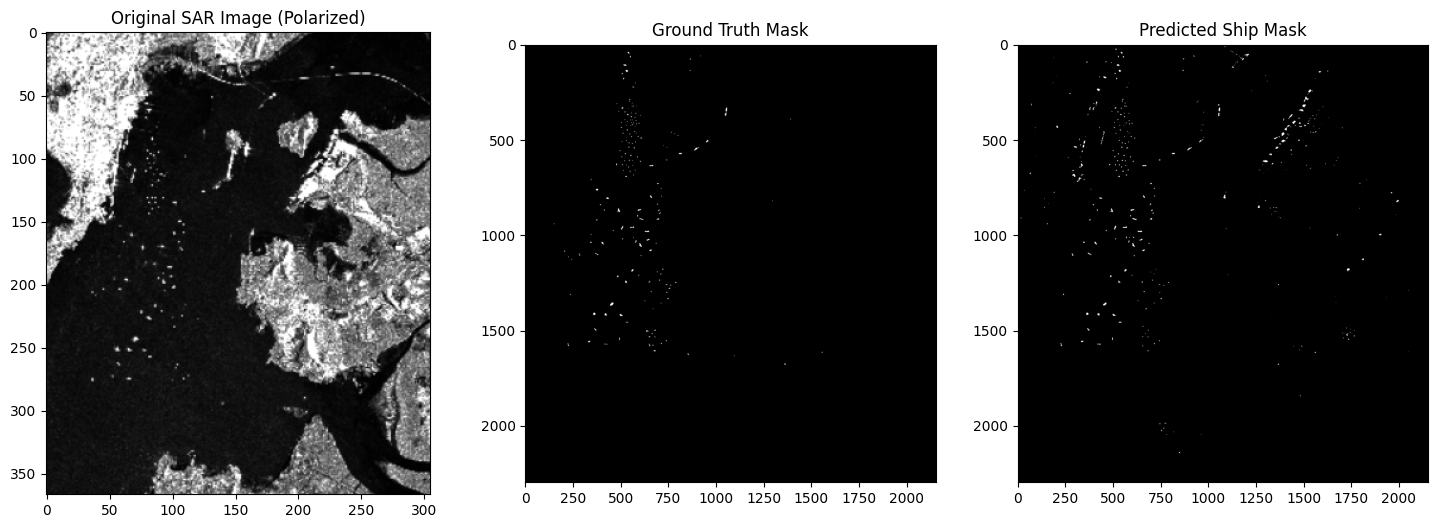

Predicted Mask Unique Values: [0 1]


In [11]:
# Visualization
import matplotlib.pyplot as plt
import rasterio
import numpy as np

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.title('Original SAR Image (Polarized)')  # Updated title for clarity
with rasterio.open("/kaggle/input/final-map-ref/Output_Image.png") as src:
    sar_image = src.read(1)  # Read the first band (assuming single-band or grayscale)
plt.imshow(sar_image, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('Ground Truth Mask')
with rasterio.open("/kaggle/input/ship-detecion-dataset/ship_detection_bw.tif") as src:
    gt_mask = (src.read(1) > 0).astype(np.uint8)
plt.imshow(gt_mask, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('Predicted Ship Mask')
plt.imshow(pred_mask, cmap='gray')
plt.show()

print(f"Predicted Mask Unique Values: {np.unique(pred_mask)}")  # Debug print

In [12]:
# Performance Evaluation
import numpy as np
import rasterio

def dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection) / (np.sum(y_true) + np.sum(y_pred) + 1e-8)  # Add small epsilon to avoid division by zero

def iou(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return intersection / (union + 1e-8)  # Add small epsilon to avoid division by zero

# Load ground truth mask
with rasterio.open("/kaggle/input/ship-detecion-dataset/ship_detection_bw.tif") as src:
    gt_mask = (src.read(1) > 0).astype(np.uint8)

# Compute performance metrics
dice = dice_coefficient(gt_mask, pred_mask)
iou_score = iou(gt_mask, pred_mask)

# Display results
print(f" Dice Coefficient: {dice:.4f}")
print(f" IoU: {iou_score:.4f}")
print(f"Predicted Mask Unique Values: {np.unique(pred_mask)}")  # For consistency with debug print

 Dice Coefficient: 0.5054
 IoU: 0.3381
Predicted Mask Unique Values: [0 1]
